# Part 1: Làm sạch & Tích hợp Dữ liệu Đa nguồn
**Thành viên phụ trách:** Thành viên 1 | **Nhánh Git:** `feature/cleaning-integration`

Notebook trình bày: (1) đánh giá dữ liệu thiếu / sai định dạng, (2) khử trùng lặp 3 cấp bằng **hàm băm SHA-256**,
(3) tích hợp chuyến bay đi/đến + thời tiết + tải sân bay, (4) kiểm tra tính nhất quán sau tích hợp (Cohen's Kappa),
(5) đối chiếu tỷ lệ trễ/OTP các hãng với số liệu Cục Hàng không (CAAV).

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent          # notebook nằm trong notebooks/
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

import config
import pipeline.processor as P
from pipeline.transformation import apply_labels

THRESHOLD = 15
HAS_RAW = any((ROOT / "data" / "raw").glob("*.csv")) or (ROOT / "data" / "debug_data").exists()
FIG_DIR = ROOT.parent / "tv1_figures"          # ngoài git
FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110

def save(name):
    plt.tight_layout()
    try:
        plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    except Exception:
        fallback = ROOT / "docs" / "images"
        fallback.mkdir(parents=True, exist_ok=True)
        plt.savefig(fallback / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Gốc repo:", ROOT)
print("Có dữ liệu thô (data/raw hoặc debug_data):", HAS_RAW)

Gốc repo: D:\datamining_nhom8_updated
Có dữ liệu thô (data/raw hoặc debug_data): True


## 2. Đọc & tích hợp dữ liệu đa nguồn
`P.prepare_dataset()` đọc `data/raw/*.csv` (5 bảng FIDS sân bay + Aviationstack API), chuẩn hóa về schema chung `FIELDS`,
khử trùng lặp 3 cấp và ghép thời tiết Open-Meteo + tải sân bay theo `(airport, giờ bay)`.

In [2]:
if HAS_RAW:
    side, leg, stats, per_src = P.prepare_dataset()
    print(f"Snapshot thô:                 {stats['snapshots']:,}")
    print(f"Trùng tuyệt đối (raw_hash):   {stats['exact_duplicates']:,}")
    print(f"Sau cấp 0 (raw_hash):         {stats['after_exact_dedup']:,}")
    print(f"Sau cấp 1 (event_hash):       {stats['after_side_dedup']:,}")
    print(f"Sau cấp 2 (leg_hash):         {stats['after_leg_dedup']:,}")
    print(f"Chuyến thấy ở cả 2 phía:      {stats['legs_seen_both_sides']:,}")
else:
    print("Không có data/raw -> các mục 3-5 bị bỏ qua, mục 6-7 đọc thẳng FILE_CLEANED.")

Snapshot thô:                 93,581
Trùng tuyệt đối (raw_hash):   10
Sau cấp 0 (raw_hash):         93,571
Sau cấp 1 (event_hash):       19,887
Sau cấp 2 (leg_hash):         14,005
Chuyến thấy ở cả 2 phía:      5,359


## 3. Dữ liệu thiếu & sai định dạng (dữ liệu THÔ, trước làm sạch)
Quy tắc định dạng: `flight_date` = `YYYY-MM-DD`; `scheduled_time` = `HH:MM`; `flight_no` = mã hãng 2 ký tự + 1–4 chữ số;
`direction` ∈ {DEPARTURES, ARRIVALS}; `airport` = mã IATA 3 chữ cái.

,Cột,Thiếu,Thiếu (%),Sai định dạng,Sai định dạng (%)
0,source,0,0.00,NaN,NaN
1,airport,0,0.00,0.0,0.00
2,direction,0,0.00,0.0,0.00
3,scraped_at,0,0.00,NaN,NaN
4,flight_date,0,0.00,0.0,0.00
5,airline_code,3526,3.77,NaN,NaN
6,flight_no,0,0.00,3526.0,3.77
7,other_airport,0,0.00,NaN,NaN
8,scheduled_time,0,0.00,37.0,0.04
9,estimated_time,350,0.37,NaN,NaN


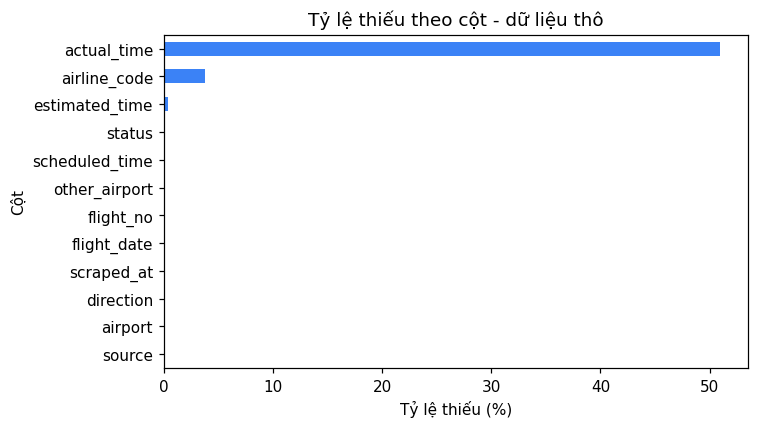

In [3]:
if HAS_RAW:
    fr = stats["format_report"]
    display(fr)
    ax = fr.set_index("Cột")["Thiếu (%)"].sort_values().plot(kind="barh", figsize=(7, 4), color="#3b82f6")
    ax.set_xlabel("Tỷ lệ thiếu (%)"); ax.set_title("Tỷ lệ thiếu theo cột - dữ liệu thô")
    save("01_missing_raw")

In [4]:
if HAS_RAW:
    print("Tên sân bay đầu kia chưa ánh xạ được mã IATA (top 20):")
    display(stats["unmapped_top"].to_frame("Số bản ghi"))

Tên sân bay đầu kia chưa ánh xạ được mã IATA (top 20):


,Số bản ghi
other_airport,


**Cách xử lý:**
- `actual_time` trống nhưng trạng thái đã cất/hạ cánh (`Departed`, `Arrived`, `Landed`…) → điền từ `estimated_time` (giờ cập nhật trên FIDS).
- `estimated_time` / `actual_time` trống ở chuyến chưa bay là **thiếu hợp lệ** (chưa xảy ra), không điền.
- Chuẩn hóa in hoa + bỏ khoảng trắng các cột khóa; số hiệu chuyến bỏ khoảng trắng và số 0 đứng đầu (`VN 0213` → `VN213`).
- Tên sân bay đầu kia (`Ha Noi (HAN)`, `Da Nang`…) được ánh xạ sang mã IATA; bản ghi không ánh xạ được vẫn giữ nhưng dùng khóa dự phòng.
- Chỉ giữ 7 hãng Việt Nam (`VN, VJ, QH, BL, VU, 9G, 0V`); tải sân bay được tính **trước** khi lọc (tính trên mọi hãng).

### 3.1. Trực quan hóa tiến trình xử lý khuyết `actual_time` qua 3 giai đoạn

- **Giai đoạn 1 (Dữ liệu thô - Raw Snapshots):** Khuyết **47,199 / 93,074 dòng (50.71%)** do crawler thu thập lặp nhiều lần các chuyến bay tương lai trong ngày chưa cất cánh.
- **Giai đoạn 2 (`flights_cleaned.csv` - TV1):** Giảm xuống **1,853 / 13,965 chuyến (13.27%)** nhờ:
  - Khử trùng lặp 3 cấp bằng hàm băm **SHA-256** (giữ lại bản ghi snapshot mới nhất và đầy đủ nhất).
  - **Điền khuyết chéo:** Các chuyến bay đã hoàn tất (`Departed`/`Arrived`/`Landed`) mà thiếu `actual_time` thì lấy từ `estimated_time` bù sang.
- **Giai đoạn 3 (`flights_features.csv` - TV2):** Giảm xuống **120 / 13,965 chuyến (0.86%)** nhờ quy tắc nghiệp vụ hàng không:
  - Chuyến `on_time`: lấy `scheduled_time`.
  - Chuyến `delayed`: tính từ `scheduled_time + delay_min`.
  - **119 chuyến còn lại là chuyến bay bị hủy (`cancelled`) $\rightarrow$ bắt buộc phải là `NaN` theo logic hàng không (máy bay không cất cánh nên không có giờ thực tế).**


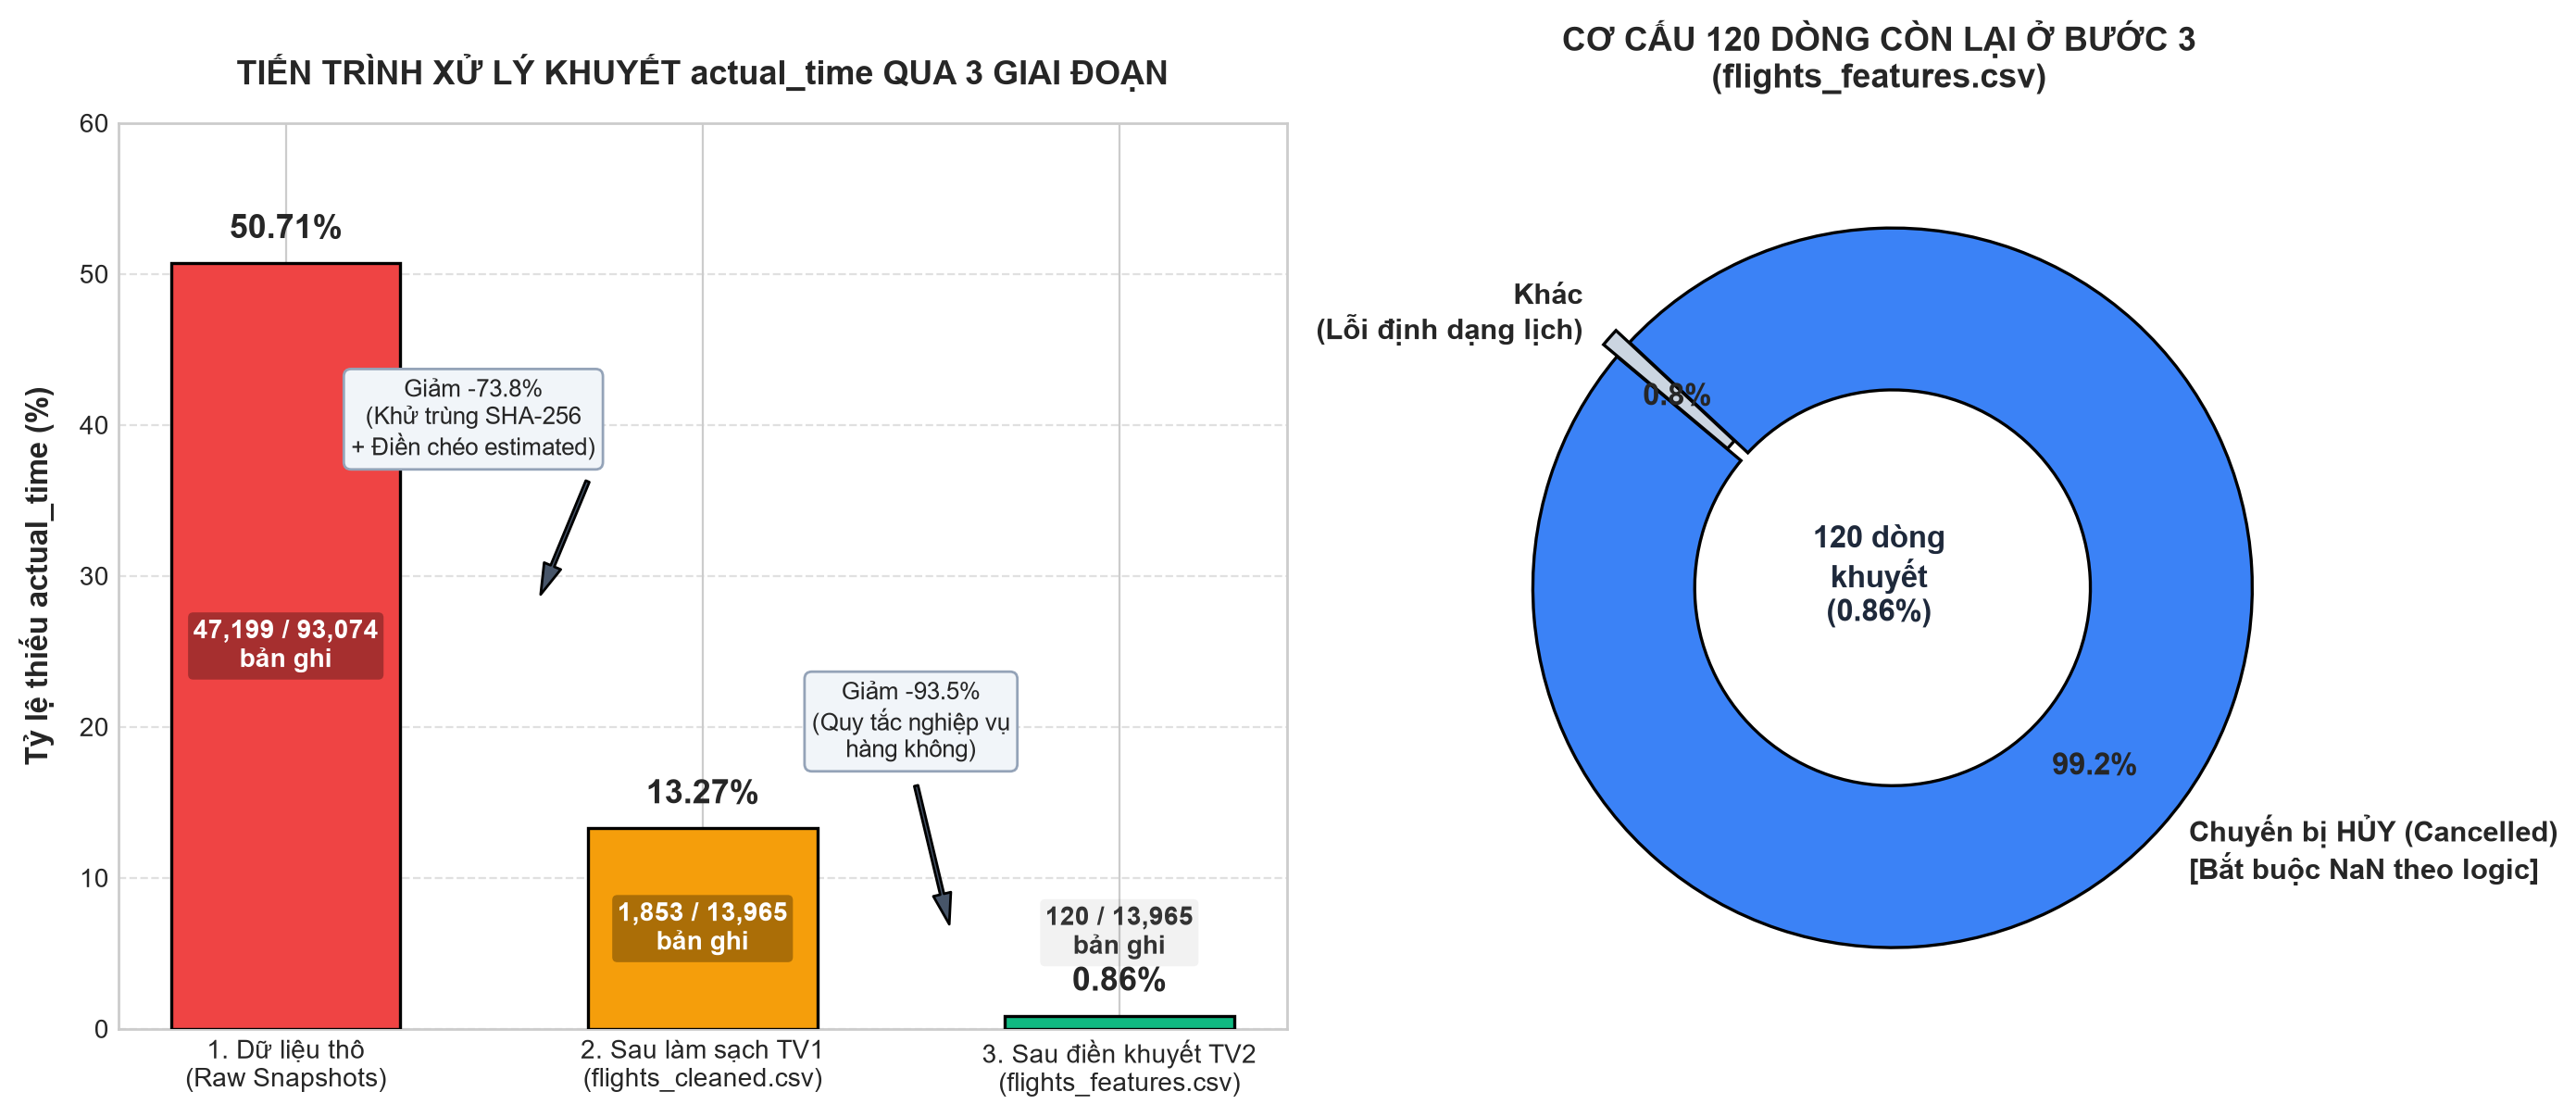

In [6]:
# Trực quan hóa tiến trình giảm khuyết actual_time qua 3 giai đoạn
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})

# Panel 1: Biểu đồ cột tiến trình giảm khuyết
stages = [
    "1. Dữ liệu thô\n(Raw Snapshots)",
    "2. Sau làm sạch TV1\n(flights_cleaned.csv)",
    "3. Sau điền khuyết TV2\n(flights_features.csv)"
]
pcts = [50.71, 13.27, 0.86]
counts = [47199, 1853, 120]
totals = [93074, 13965, 13965]
colors = ["#ef4444", "#f59e0b", "#10b981"]

bars = ax1.bar(stages, pcts, color=colors, width=0.55, edgecolor="black", linewidth=1.2, zorder=3)
ax1.grid(axis="y", linestyle="--", alpha=0.6, zorder=0)
ax1.set_ylabel("Tỷ lệ thiếu actual_time (%)", fontsize=11, fontweight="bold")
ax1.set_title("TIẾN TRÌNH XỬ LÝ KHUYẾT actual_time QUA 3 GIAI ĐOẠN", fontsize=12, fontweight="bold", pad=12)
ax1.set_ylim(0, 60)

for bar, pct, cnt, tot in zip(bars, pcts, counts, totals):
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 1.2, f"{pct:.2f}%", ha="center", va="bottom", fontsize=11, fontweight="bold")
    ax1.text(bar.get_x() + bar.get_width()/2, h/2 if h > 5 else h + 5.5, f"{cnt:,} / {tot:,}\nbản ghi", 
             ha="center", va="center", fontsize=9, fontweight="bold", 
             color="white" if h > 5 else "#333333",
             bbox=dict(boxstyle="round,pad=0.2", facecolor="black", alpha=0.3 if h > 5 else 0.05, edgecolor="none"))

ax1.annotate("Giảm -73.8%\n(Khử trùng SHA-256\n+ Điền chéo estimated)", 
             xy=(0.6, 28), xytext=(0.45, 38),
             arrowprops=dict(facecolor="#475569", shrink=0.08, width=1.5, headwidth=6),
             fontsize=8.5, ha="center", bbox=dict(boxstyle="round,pad=0.25", facecolor="#f1f5f9", edgecolor="#94a3b8"))

ax1.annotate("Giảm -93.5%\n(Quy tắc nghiệp vụ\nhàng không)", 
             xy=(1.6, 6), xytext=(1.5, 18),
             arrowprops=dict(facecolor="#475569", shrink=0.08, width=1.5, headwidth=6),
             fontsize=8.5, ha="center", bbox=dict(boxstyle="round,pad=0.25", facecolor="#f1f5f9", edgecolor="#94a3b8"))

# Panel 2: Biểu đồ Donut giải trình 120 dòng khuyết còn lại
labels = ["Chuyến bị HỦY (Cancelled)\n[Bắt buộc NaN theo logic]", "Khác\n(Format ký tự)"]
sizes = [119, 1]
donut_colors = ["#3b82f6", "#cbd5e1"]

wedges, texts, autotexts = ax2.pie(
    sizes, explode=(0.05, 0), labels=labels, autopct="%1.1f%%",
    startangle=140, colors=donut_colors,
    wedgeprops=dict(width=0.45, edgecolor="black", linewidth=1.2),
    textprops=dict(fontsize=10, fontweight="bold"), pctdistance=0.75
)
for at in autotexts:
    at.set_fontsize(11); at.set_fontweight("bold")

ax2.set_title("CƠ CẤU 120 DÒNG CÒN LẠI Ở BƯỚC 3\n(flights_features.csv)", fontsize=12, fontweight="bold", pad=12)
ax2.text(0, 0, "120 dòng\nkhuyết\n(0.86%)", ha="center", va="center", fontsize=11, fontweight="bold", color="#1e293b")

save("01_actual_time_imputation_progression")


## 4. Khử trùng lặp bằng hàm băm SHA-256
Mỗi cấp nối các cột khóa đã chuẩn hóa thành 1 chuỗi `A|B|C…`, băm SHA-256 và lấy 16 ký tự hex đầu (64 bit).
Hai bản ghi trùng khóa ⇔ trùng mã băm, nên chỉ cần so 1 cột thay vì nhiều cột.

| Cấp | Cột băm | Khóa băm | Quy tắc giữ bản ghi |
|---|---|---|---|
| 0 – trùng tuyệt đối | `raw_hash` | cả 12 cột `FIELDS` | giữ 1 bản (bản sau cùng) |
| 1 – cùng phía sân bay | `event_hash` | `airport, direction, flight_date, flight_no, scheduled_time` | giàu thông tin nhất (`has_info`, `has_done_act`) rồi mới nhất (`scraped_at`) |
| 2 – cấp chuyến bay | `leg_hash` | `leg_key` = `flight_no|flight_date|origin>destination` | gộp bảng đi + bảng đến; ưu tiên giàu thông tin, sân bay có theo dõi, phía DEPARTURES, mới nhất |

,flight_no,flight_date,airport,direction,scheduled_time,source,raw_hash,event_hash,leg_hash,leg_key
1064,0V106,2026-10-28,CXR,DEPARTURES,12:42,guide_cxr,70f3abb1a739f69a,8a9267b902a76aa6,64eaeb6c8853068e,0V106|2026-10-28|CXR>HAN
3548,0V106,2026-10-28,DAD,DEPARTURES,12:42,guide_dad,f76429859bcff075,a9badf2298ee3dc3,a80b37e5f323a374,0V106|2026-10-28|DAD>HAN
451,0V106,2026-10-28,CXR,ARRIVALS,12:42,guide_cxr,3ac3fd897ea52ec9,00a3f1a968969590,b7e0bd2fda3e3a80,0V106|2026-10-28|HAN>CXR
2164,0V106,2026-10-28,DAD,ARRIVALS,12:42,guide_dad,838dd8aaae67585a,a95afcf411d31c3e,bcca0f508b9ec432,0V106|2026-10-28|HAN>DAD
11105,0V106,2026-10-28,PQC,ARRIVALS,12:42,guide_pqc,be770bc57003a6e3,1f17284d83bf5f65,9a865a9c88086f1c,0V106|2026-10-28|HAN>PQC


,Số dòng
Snapshot thô,93581
Cấp 0: raw_hash,93571
Cấp 1: event_hash\n(hãng VN),19887
Cấp 2: leg_hash,14005


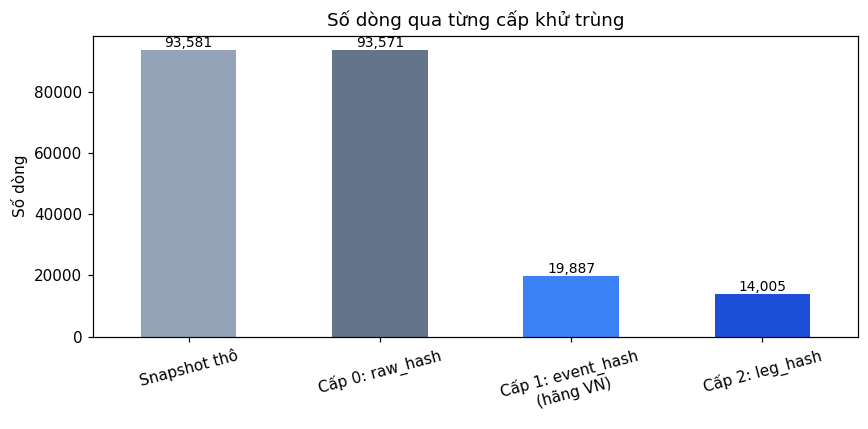

In [5]:
if HAS_RAW:
    display(side[["flight_no", "flight_date", "airport", "direction", "scheduled_time", "source",
                  "raw_hash", "event_hash", "leg_hash", "leg_key"]].head(5))
    funnel = pd.Series({
        "Snapshot thô": stats["snapshots"],
        "Cấp 0: raw_hash": stats["after_exact_dedup"],
        "Cấp 1: event_hash\n(hãng VN)": stats["after_side_dedup"],
        "Cấp 2: leg_hash": stats["after_leg_dedup"],
    }).astype(int)
    display(funnel.to_frame("Số dòng"))
    ax = funnel.plot(kind="bar", figsize=(8, 4), color=["#94a3b8", "#64748b", "#3b82f6", "#1d4ed8"])
    for i, v in enumerate(funnel):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
    ax.set_ylabel("Số dòng"); ax.set_title("Số dòng qua từng cấp khử trùng"); plt.xticks(rotation=15)
    save("02_dedup_funnel")

## 5. Kiểm tra tính nhất quán sau tích hợp

In [6]:
if HAS_RAW:
    ir = P.integration_report(leg)
    display(ir)

,Kiểm tra,Đạt (%),Số dòng
0,Ghép được sân bay đầu kia (leg_matched),100.00,14005
1,Chuyến thấy ở cả bảng đi và bảng đến,38.26,14005
2,Sự kiện có >= 2 nguồn ghi nhận,5.71,14005
3,Ghép được thời tiết (precipitation có giá trị),99.64,14005
4,Ghép được tải sân bay (airport_load),99.64,14005
5,origin != destination,99.96,14005
6,leg_key duy nhất,100.00,14005


In [7]:
if HAS_RAW:
    side_l = apply_labels(side, THRESHOLD)
    sv = side_l[side_l["status_clean"].isin(P.LABELS)].assign(is_cx=lambda d: d["status_clean"].eq("cancelled"))
    g = sv.groupby("leg_key")["is_cx"].agg(["nunique", "size"])
    multi = g[g["size"] > 1]
    print(f"Nhất quán hủy/không hủy giữa các bản ghi cùng leg_key: "
          f"{(multi['nunique'] == 1).mean() * 100:.1f}% trên {len(multi):,} chuyến có >= 2 bản ghi")

Nhất quán hủy/không hủy giữa các bản ghi cùng leg_key: 99.8% trên 5,477 chuyến có >= 2 bản ghi


**Cohen's Kappa** đo mức đồng thuận nhãn (`on_time / delayed / cancelled`) giữa 2 nguồn trên cùng sự kiện,
đã loại phần trùng do ngẫu nhiên: κ = (p_o − p_e) / (1 − p_e), với p_o = tỷ lệ trùng nhãn quan sát, p_e = tỷ lệ trùng kỳ vọng nếu 2 nguồn độc lập.
Cách đọc (Landis & Koch): < 0.2 kém, 0.21–0.40 khá thấp, 0.41–0.60 trung bình, 0.61–0.80 tốt, > 0.80 rất tốt.

In [8]:
if HAS_RAW:
    sa = P.source_agreement(per_src, THRESHOLD)
    display(sa if not sa.empty else "Chưa có cặp nguồn nào đủ >= 20 sự kiện chung.")

,Nguồn A,Nguồn B,Số sự kiện chung,Trùng nhãn (%),Kappa,Lệch trễ trung vị (phút)
0,aviationstack_api,guide_cxr,46,71.7,0.473,7.0
1,aviationstack_api,guide_dad,177,72.3,0.519,6.0
2,aviationstack_api,guide_han,365,67.4,0.355,10.0
3,aviationstack_api,guide_pqc,66,72.7,0.441,10.5
4,aviationstack_api,guide_sgn,371,70.9,0.439,10.0


## 6. Dữ liệu sạch & đa nguồn

In [9]:
if HAS_RAW:
    df, rules = P.label_and_report(side, leg, stats, THRESHOLD, per_src)
    df.to_csv(config.FILE_CLEANED, index=False, encoding="utf-8-sig")
    print(f"Đã ghi {config.FILE_CLEANED.name}: {df.shape[0]:,} dòng x {df.shape[1]} cột")
else:
    df = pd.read_csv(config.FILE_CLEANED)
    print(f"Đọc {config.FILE_CLEANED.name}: {df.shape[0]:,} dòng x {df.shape[1]} cột")
assert list(df.columns) == config.CLEANED_FIELDS and df["leg_key"].is_unique
display(df["status_clean"].value_counts().to_frame("Số chuyến"))

BÁO CÁO TÍCH HỢP DỮ LIỆU (ngưỡng trễ = 15 phút)
Snapshot thô:                               93,581
Trùng tuyệt đối (cùng mã băm SHA-256):      10
Sau khử trùng cùng phía (hãng Việt Nam):    19,887
Sau khử trùng (1 chuyến=1):                 14,005
  - chuyến thấy ở cả bảng đi và bảng đến:   5,359
  - sự kiện có >=2 nguồn (cùng phía):       800
Mẫu hợp lệ cho khai phá:                    13,965 / 10,000
Nhất quán hủy/không hủy giữa các bản ghi:   99.8% (5,477 chuyến có >=2 bản ghi)
--------------------------------------------------------------
PHÂN BỐ NHÃN ĐÍCH (status_clean):
status_clean
on_time      9960
delayed      3886
cancelled     119

PHÂN BỐ TRẠNG THÁI CHI TIẾT (status_detail):
status_detail
departed_on_time    5714
arrived_on_time     2834
departed_late       2334
on_time             1412
arrived_late        1230
delayed              322
cancelled            119

Chuyến bị loại vì chưa có nhãn cuối (unknown): 40 / 14,005
TỶ LỆ THEO HÃNG (so với số liệu chính thức)
Hãng  Số ch

,Số chuyến
status_clean,
on_time,9960
delayed,3886
cancelled,119


,Số chuyến
source,
guide_sgn,5210
guide_han,4076
guide_dad,1709
guide_pqc,1262
aviationstack_api,914
guide_cxr,794


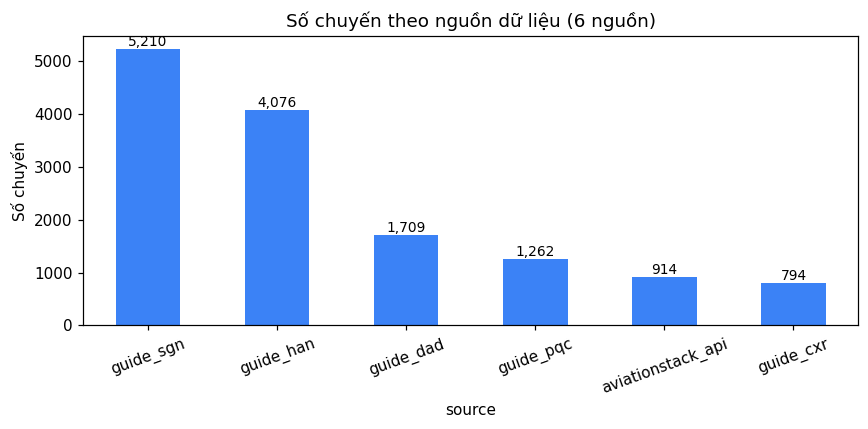

In [10]:
src = df["source"].value_counts()
display(src.to_frame("Số chuyến"))
ax = src.plot(kind="bar", figsize=(8, 4), color="#3b82f6")
for i, v in enumerate(src):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Số chuyến"); ax.set_title(f"Số chuyến theo nguồn dữ liệu ({src.size} nguồn)"); plt.xticks(rotation=20)
save("03_source_counts")

## 7. Tỷ lệ trễ / OTP các hãng so với CAAV

,Hãng,Số chuyến,Trễ (%),Hủy (%),OTP (%),Chính thức: trễ,Chính thức: hủy,Chính thức: OTP
7,ALL,13965,27.8,0.85,71.3,22.3,0.6,
5,VN,5439,23.9,1.60,74.5,,,78.0
4,VJ,5107,38.8,0.23,61.0,,,75.2
1,9G,1919,15.3,0.42,84.3,,,
6,VU,587,23.2,0.34,76.5,,,
0,0V,501,12.2,1.60,86.2,,,
2,BL,324,20.4,0.62,79.0,,,
3,QH,88,58.0,0.00,42.0,,,


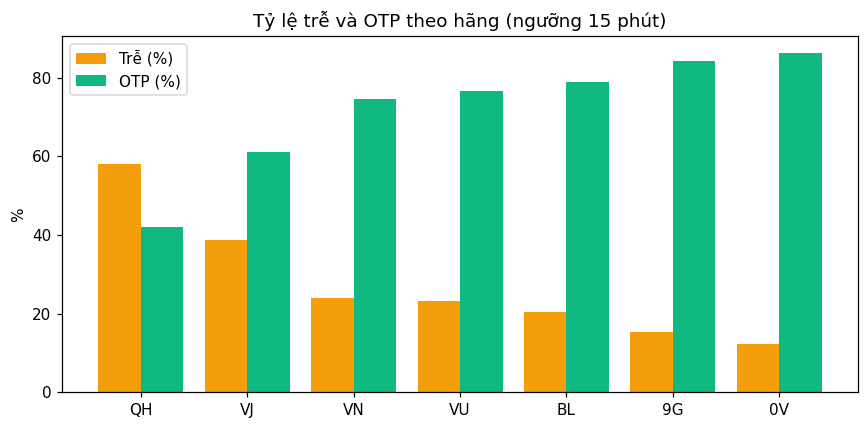

In [11]:
al = P.airline_table(df)
display(al)
pl = al[al["Hãng"] != "ALL"].sort_values("Trễ (%)", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(pl))
ax.bar(x - 0.2, pl["Trễ (%)"], 0.4, label="Trễ (%)", color="#f59e0b")
ax.bar(x + 0.2, pl["OTP (%)"], 0.4, label="OTP (%)", color="#10b981")
ax.set_xticks(x, pl["Hãng"]); ax.set_ylabel("%"); ax.legend()
ax.set_title(f"Tỷ lệ trễ và OTP theo hãng (ngưỡng {THRESHOLD} phút)")
save("04_airline_delay_otp")

**Kết luận & bàn giao cho TV2:**
- `data/flights_cleaned_global.csv` đúng 24 cột theo `CLEANED_FIELDS`, 1 dòng = 1 chặng bay (`leg_key` duy nhất), đã ghép thời tiết và tải sân bay.
- Các cột băm (`raw_hash`, `event_hash`, `leg_hash`) chỉ là cột trung gian, không xuất ra file.
- TV2 dùng file này cho `check_data.py` (data contract) và bước biến đổi dữ liệu.